---

# Tugas Besar 2 IF3170: Prediksi Pembatalan Pemesanan Penginapan

*Eksperimen `knn_baseline`: K-Nearest Neighbors from scratch, dibandingkan dengan scikit-learn.*

---

## Kelompok 17 DerbyCounty

- NIM - Nama
- NIM - Nama
- NIM - Nama
- NIM - Nama
- NIM - Manu (pemegang KNN)

---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Data Preparation**](#3)
4. [**Modeling dan Validation**](#4)
5. [**Perbandingan dengan scikit-learn**](#5)
6. [**Analisis Sensitivitas k**](#6)
7. [**Submission**](#7)

---

# Introduction <a name="1"></a>

---

## Aim

*Membangun baseline KNN from scratch (`src/models/knn.py`) dengan preprocessing `KNNPreprocessor` (`src/preprocessing/knn.py`), memvalidasinya dengan stratified 5-fold yang sama seperti model lain, lalu membandingkannya dengan `sklearn.neighbors.KNeighborsClassifier` pada fold dan hasil preprocessing yang identik.*

## Approach

| Komponen | Konfigurasi |
| --- | --- |
| Cleaning | `clean_train`: buang duplikat; `mark_invalid`: `num_adults = 0` jadi NaN |
| Feature engineering | **tidak ada** (`feature_engineering=False`) |
| Transformasi | indikator missing, imputasi median/modus train, kategori langka (< 20) jadi `Other`, one-hot, standardisasi mean/std train |
| Model | KNN brute force, Euclidean (`p=2`), `k=5`, voting uniform |
| Validasi | stratified 5-fold, seed 42, threshold dari OOF (`best_threshold`) |
| Pembanding | `KNeighborsClassifier(n_neighbors=5, metric='minkowski', p=2, weights='uniform', algorithm='brute')` |

KNN adalah *lazy learner*: `fit` hanya menyimpan data train. Prediksi suatu query adalah proporsi label 1 di antara `k` tetangga terdekat. Jarak Euclidean sangat sensitif terhadap skala, sehingga standardisasi wajib dilakukan.

---

# Initialization <a name="2"></a>

---

## Import Libraries

In [1]:
import hashlib
import os
import random
import sys
import time
from pathlib import Path

os.environ.setdefault('LOKY_MAX_CPU_COUNT', '1')  # hindari peringatan joblib di Windows

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.neighbors import KNeighborsClassifier

# Cari folder root repo agar notebook bisa dijalankan dari folder mana pun
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src' / 'models').is_dir())
sys.path.insert(0, str(ROOT / 'src'))

from models import KNN
from preprocessing import TARGET, KNNPreprocessor, clean_train
from utils import (best_threshold, confusion_matrix, cross_val_proba, f1_per_class,
                   fold_scores, load_model, macro_f1, save_model, stratified_kfold)

print('python', sys.version.split()[0], '| numpy', np.__version__, '| pandas', pd.__version__,
      '| scikit-learn', sklearn.__version__, '| matplotlib', matplotlib.__version__)

python 3.13.0 | numpy 2.2.6 | pandas 2.2.3 | scikit-learn 1.6.1 | matplotlib 3.10.3


## Settings

In [2]:
class Settings:
    SEED       = 42
    DATA_DIR   = ROOT / 'data'
    OUTPUT_DIR = ROOT / 'output'
    N_FOLDS    = 5

    PREP_PARAMS = dict(feature_engineering=False, rare_min_count=20, drop_cols=None)
    KNN_PARAMS  = dict(k=5, p=2, weights='uniform')
    K_GRID      = [1, 3, 5, 7, 9, 11, 15, 21, 31, 41, 51]

    EXP_NAME   = 'knn_baseline'
    MODEL_PATH = OUTPUT_DIR / 'models' / f'{EXP_NAME}.pkl'
    SUB_PATH   = OUTPUT_DIR / 'submissions' / f'submission_{EXP_NAME}.csv'
    FIG_DIR    = OUTPUT_DIR / 'figures'

CFG = Settings()
for d in (CFG.SUB_PATH.parent, CFG.MODEL_PATH.parent, CFG.FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

## Seed Everything

KNN from scratch tidak memakai sumber acak; seed hanya dipakai pembagian fold.

In [3]:
def seed_everything(seed: int = 42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)

seed_everything(CFG.SEED)

## Load Dataset

In [4]:
train_raw = pd.read_csv(CFG.DATA_DIR / 'train.csv', dtype={'id': str})
test_raw  = pd.read_csv(CFG.DATA_DIR / 'test.csv', dtype={'id': str})
sample    = pd.read_csv(CFG.DATA_DIR / 'sample_submission.csv', dtype={'id': str})

print('train ', train_raw.shape)
print('test  ', test_raw.shape)

train  (27373, 19)
test   (6844, 18)


---

# Data Preparation <a name="3"></a>

---

## 3.1 Data Understanding Singkat untuk KNN

Dua hal paling berpengaruh bagi KNN: (1) missing values harus diisi sebelum jarak dihitung, dan (2) rentang fitur sangat berbeda, sehingga tanpa scaling `nightly_rate_idr` akan mendominasi jarak.

In [5]:
summary = pd.DataFrame({
    'missing': train_raw.isna().sum(),
    'min': train_raw.min(numeric_only=True),
    'max': train_raw.max(numeric_only=True),
}).loc[lambda d: d['missing'].gt(0) | d['max'].notna()]
print('proporsi target:', train_raw[TARGET].value_counts(normalize=True).round(4).to_dict())
summary

proporsi target: {0: 0.6723, 1: 0.3277}


,missing,min,max
arrival_day,0,1.0,31.0
arrival_month,0,1.0,12.0
arrival_year,0,2023.0,2024.0
days_before_arrival,1123,0.0,448.0
is_canceled,0,0.0,1.0
is_returning_guest,0,0.0,1.0
meal_package,1760,NaN,NaN
needs_parking,1082,0.0,1.0
nightly_rate_idr,2038,0.0,9165000.0
num_adults,809,0.0,4.0


## 3.2 Data Cleaning dan Transformation

Cleaning memakai fungsi bersama. `KNNPreprocessor` hanya di-fit pada data train (atau train fold), lalu `transform` dipakai untuk validasi dan test sehingga skema kolom selalu sama.

In [6]:
train = clean_train(train_raw)
y = train[TARGET].to_numpy()

def make_prep():
    return KNNPreprocessor(**CFG.PREP_PARAMS)

prep_check = make_prep()
X_check = prep_check.fit_transform(train)
X_test_check = prep_check.transform(test_raw)
print('sebelum', train_raw.shape, ' sesudah', train.shape)
print('fitur  ', X_check.shape[1], '| test', X_test_check.shape)
print('finite ', np.isfinite(X_check.to_numpy()).all() and np.isfinite(X_test_check.to_numpy()).all())
print('kolom sama train/test', list(X_check.columns) == list(X_test_check.columns))
print(list(X_check.columns))

sebelum (27373, 19)  sesudah (27309, 19)
fitur   39 | test (6844, 39)
finite  True
kolom sama train/test True
['num_adults_missing', 'num_children_missing', 'meal_package_missing', 'needs_parking_missing', 'room_category_missing', 'days_before_arrival_missing', 'nightly_rate_idr_missing', 'special_requests_missing', 'num_adults', 'num_children', 'weekend_nights', 'weekday_nights', 'needs_parking', 'days_before_arrival', 'arrival_year', 'arrival_month', 'arrival_day', 'is_returning_guest', 'prior_cancellations', 'prior_completed_bookings', 'nightly_rate_idr', 'special_requests', 'meal_package_Breakfast', 'meal_package_Half Board', 'meal_package_Room Only', 'meal_package_Other', 'room_category_Type A', 'room_category_Type B', 'room_category_Type C', 'room_category_Type D', 'room_category_Type F', 'room_category_Type G', 'room_category_Other', 'booking_channel_Airline', 'booking_channel_Complimentary', 'booking_channel_Corporate', 'booking_channel_Offline Agent', 'booking_channel_Online T

#### Insights

> Hasil preprocessing berisi 39 kolom numerik: 14 fitur numerik asli, 17 kolom one-hot dari 3 fitur kategorikal (termasuk `Other`), dan 8 indikator missing. Seluruh nilai finite, dan train/test memiliki urutan kolom yang sama. Seleksi fitur, resampling untuk imbalance (rasio sekitar 67:33), dan PCA sengaja tidak dipakai pada baseline. Belum ada bukti validasi bahwa langkah tersebut membantu, dan mengubah jumlah sampel langsung mengubah komposisi tetangga KNN. Imbalance ditangani lewat pemilihan threshold pada OOF dan metrik Macro F1.

---

# Modeling dan Validation <a name="4"></a>

---

## 4.1 Sanity Check pada Contoh Kecil

Train 1D `x = [0, 1, 2, 3, 4, 5]` dengan label `[0, 0, 1, 1, 1, 0]`, `k = 3`. Untuk query `0.1`, tetangganya `0, 1, 2` (jarak 0.1, 0.9, 1.9), sehingga probabilitasnya 1/3 dan labelnya 0. Untuk query `3`, tetangganya `3, 2, 4`, sehingga probabilitasnya 1. Untuk query `5.2`, tetangganya `5, 4, 3`, sehingga probabilitasnya 2/3 dan labelnya 1.

In [7]:
toy = KNN(k=3).fit(np.arange(6.).reshape(-1, 1), [0, 0, 1, 1, 1, 0])
d, idx = toy.kneighbors([[.1], [3.], [5.2]])
print('indeks', idx.tolist())
print('jarak ', d.round(2).tolist())
print('proba ', toy.predict_proba([[.1], [3.], [5.2]]).round(4).tolist())
print('label ', toy.predict([[.1], [3.], [5.2]]).tolist())

indeks [[0, 1, 2], [3, 2, 4], [5, 4, 3]]
jarak  [[0.1, 0.9, 1.9], [0.0, 1.0, 1.0], [0.2, 1.2, 2.2]]
proba  [0.3333, 1.0, 0.6667]
label  [0, 1, 1]


## 4.2 Validasi Silang KNN from Scratch

Fold dibuat dari `y` hasil cleaning dengan seed 42, sehingga identik dengan fold model lain. Pada setiap fold, `cross_val_proba` membuat preprocessor baru yang hanya di-fit pada train fold.

In [8]:
folds = stratified_kfold(y, n_splits=CFG.N_FOLDS, seed=CFG.SEED)

t0 = time.time()
oof = cross_val_proba(lambda: KNN(**CFG.KNN_PARAMS), make_prep, train, y, folds)
time_scratch = time.time() - t0

THRESHOLD, oof_score = best_threshold(y, oof)
per_fold = fold_scores(y, oof, folds, THRESHOLD)
score_05 = macro_f1(y, (oof >= .5).astype(int))
cm = confusion_matrix(y, (oof >= THRESHOLD).astype(int))

print(f'waktu CV       {time_scratch:.1f} s')
print(f'Macro F1 @0.5  {score_05:.4f}')
print(f'threshold      {THRESHOLD}')
print(f'Macro F1 OOF   {oof_score:.4f}')
print(f'F1 per kelas   {f1_per_class(y, (oof >= THRESHOLD).astype(int)).round(4)}')
print(f'per fold       {per_fold.round(4)}')
print(f'mean / std     {per_fold.mean():.4f} / {per_fold.std():.4f}')
print('confusion matrix [[TN, FP], [FN, TP]]')
print(cm)

waktu CV       92.0 s
Macro F1 @0.5  0.7632
threshold      0.41
Macro F1 OOF   0.7632
F1 per kelas   [0.8519 0.6746]
per fold       [0.7632 0.7607 0.7688 0.7591 0.7644]
mean / std     0.7632 / 0.0034
confusion matrix [[TN, FP], [FN, TP]]
[[15991  2374]
 [ 3184  5760]]


#### Insights

> Dengan `k = 5` dan voting uniform, probabilitas hanya bisa bernilai {0, 0.2, 0.4, 0.6, 0.8, 1}. Karena itu semua threshold dalam rentang (0.4, 0.6] menghasilkan label yang sama dengan threshold 0.5. `best_threshold` mengembalikan nilai pertama pada grid yang mencapai skor maksimum. Macro F1 pada threshold tetap 0.5 dan threshold OOF pun sama.

---

# Perbandingan dengan scikit-learn <a name="5"></a>

---

## 5.1 Validasi Silang `KNeighborsClassifier`

Pembungkus kecil di bawah hanya menyesuaikan antarmuka scikit-learn dengan kontrak pipeline (`predict_proba` mengembalikan probabilitas kelas 1). Fold dan preprocessing identik dengan versi from scratch.

In [9]:
class SklearnKNN:
    def __init__(self, **params):
        self.model = KNeighborsClassifier(**params)

    def fit(self, X, y):
        self.model.fit(np.asarray(X), y)
        return self

    def predict_proba(self, X):
        return self.model.predict_proba(np.asarray(X))[:, 1]

    # scikit-learn memilih kelas 0 saat proba tepat 0.5 (argmax pada kelas pertama).
    def predict(self, X):
        return self.model.predict(np.asarray(X))

SK_PARAMS = dict(n_neighbors=5, metric='minkowski', p=2, weights='uniform', algorithm='brute')

t0 = time.time()
oof_sk = cross_val_proba(lambda: SklearnKNN(**SK_PARAMS), make_prep, train, y, folds)
time_sk = time.time() - t0
thr_sk, score_sk = best_threshold(y, oof_sk)

diff = np.abs(oof - oof_sk)
print(f'waktu CV sklearn            {time_sk:.1f} s (scratch {time_scratch:.1f} s)')
print(f'baris dengan proba berbeda  {int((diff > 0).sum())} dari {len(y)}')
print(f'selisih proba maksimum      {diff.max():.3g}')
print(f'label @0.5 sama             {np.array_equal(oof >= .5, oof_sk >= .5)}')

waktu CV sklearn            9.1 s (scratch 92.0 s)
baris dengan proba berbeda  0 dari 27309
selisih proba maksimum      0
label @0.5 sama             True


## 5.2 Ringkasan Perbandingan

Label scikit-learn di threshold 0.5 mengikuti aturan `predict` scikit-learn (kelas 0 saat suara imbang, setara `proba > 0.5`). Versi from scratch memakai `proba >= 0.5`. Dengan `k = 5` ganjil, voting uniform tidak bisa imbang, sehingga kedua aturan memberi label yang sama.

In [10]:
pred_sk_05 = (oof_sk > .5).astype(int)  # setara KNeighborsClassifier.predict
comparison = pd.DataFrame({
    'scratch @thr': per_fold,
    'sklearn @thr': fold_scores(y, oof_sk, folds, thr_sk),
}, index=[f'fold {k}' for k in range(CFG.N_FOLDS)])
comparison.loc['OOF @thr'] = [oof_score, score_sk]
comparison.loc['OOF @0.5'] = [score_05, macro_f1(y, pred_sk_05)]
comparison.loc['threshold'] = [THRESHOLD, thr_sk]
comparison['selisih'] = comparison['scratch @thr'] - comparison['sklearn @thr']
comparison.round(4)

,scratch @thr,sklearn @thr,selisih
fold 0,0.7632,0.7632,0.0
fold 1,0.7607,0.7607,0.0
fold 2,0.7688,0.7688,0.0
fold 3,0.7591,0.7591,0.0
fold 4,0.7644,0.7644,0.0
OOF @thr,0.7632,0.7632,0.0
OOF @0.5,0.7632,0.7632,0.0
threshold,0.4100,0.4100,0.0


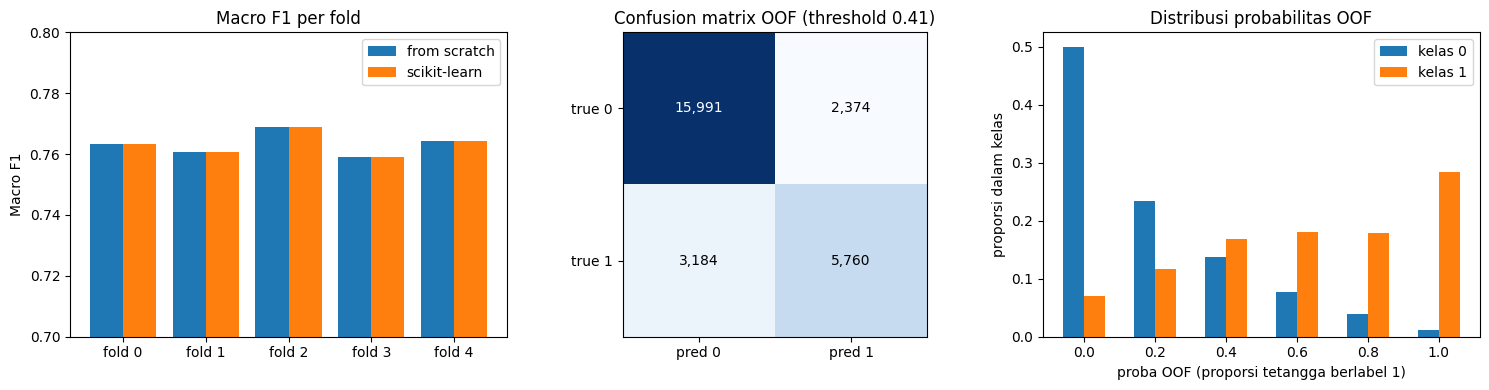

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

x = np.arange(CFG.N_FOLDS)
axes[0].bar(x - .2, comparison['scratch @thr'][:CFG.N_FOLDS], .4, label='from scratch')
axes[0].bar(x + .2, comparison['sklearn @thr'][:CFG.N_FOLDS], .4, label='scikit-learn')
axes[0].set_xticks(x, [f'fold {k}' for k in x])
axes[0].set_ylim(.70, .80)
axes[0].set_ylabel('Macro F1')
axes[0].set_title('Macro F1 per fold')
axes[0].legend()

im = axes[1].imshow(cm, cmap='Blues')
for (i, j), v in np.ndenumerate(cm):
    axes[1].text(j, i, f'{v:,}', ha='center', va='center',
                 color='white' if v > cm.max() / 2 else 'black')
axes[1].set_xticks([0, 1], ['pred 0', 'pred 1'])
axes[1].set_yticks([0, 1], ['true 0', 'true 1'])
axes[1].set_title(f'Confusion matrix OOF (threshold {THRESHOLD})')

levels = np.round(np.arange(0, 1.01, .2), 1)
axes[2].bar(levels - .03, [np.mean(oof[y == 0] == v) for v in levels], .06, label='kelas 0')
axes[2].bar(levels + .03, [np.mean(oof[y == 1] == v) for v in levels], .06, label='kelas 1')
axes[2].set_xticks(levels)
axes[2].set_xlabel('proba OOF (proporsi tetangga berlabel 1)')
axes[2].set_ylabel('proporsi dalam kelas')
axes[2].set_title('Distribusi probabilitas OOF')
axes[2].legend()

plt.tight_layout()
plt.savefig(CFG.FIG_DIR / 'knn_baseline_comparison.png', dpi=120)
plt.show()

#### Insights

> Implementasi from scratch menghasilkan probabilitas yang identik dengan `KNeighborsClassifier` untuk seluruh baris OOF. Konsekuensinya, Macro F1 per fold, threshold, dan confusion matrix juga sama. Ini membuktikan bahwa perhitungan jarak, pemilihan tetangga, dan voting sudah benar. Tie jarak di batas tetangga ke-5 memang terjadi pada sebagian kecil query (jumlahnya dicetak di bagian 6), tetapi tidak mengubah proporsi label pada data ini. Versi from scratch memilih indeks train terkecil; scikit-learn (`argpartition`) tidak menjamin urutan tersebut. Selisih yang tersisa ada di waktu komputasi, karena scikit-learn memakai perkalian matriks teroptimasi (BLAS). Versi from scratch sengaja menghitung selisih koordinat langsung demi presisi dan determinisme.
>
> Macro F1 KNN (~0.763) lebih rendah daripada Decision Tree baseline (~0.83). Penyebab yang mungkin: (1) semua fitur berbobot sama dalam jarak Euclidean, termasuk 17 kolom one-hot dan 8 indikator missing yang setelah standardisasi ikut menentukan jarak, padahal tidak semuanya relevan; (2) kutukan dimensi pada 39 fitur; (3) KNN tidak memilih fitur seperti pohon keputusan. Distribusi probabilitas OOF menunjukkan kelas 0 terkonsentrasi di 0–0.2, sedangkan kelas 1 tersebar dari 0.4 sampai 1.0, dan sekitar 19% kelas 1 justru memiliki proba ≤ 0.2 (tetangganya hampir semua kelas 0). Akibatnya, false negative (3.184) lebih banyak daripada false positive (2.374), dan F1 kelas 1 (0.675) jauh di bawah kelas 0 (0.852).

---

# Analisis Sensitivitas k <a name="6"></a>

---

Tetangga dihitung sekali per fold untuk `k` terbesar, lalu `proba_from_neighbors` memotongnya untuk setiap `k` yang lebih kecil. Hasilnya sama dengan melatih ulang setiap `k` karena urutan tetangga deterministik. Ini hanya analisis; konfigurasi submission tetap baseline `k = 5`.

query dengan tie jarak di batas ke-5 (fold terakhir): 3 dari 5461


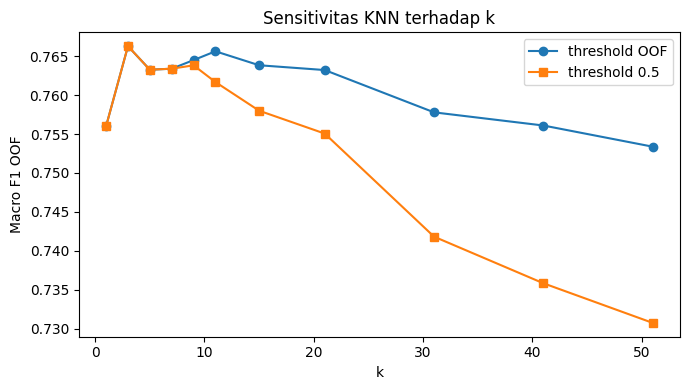

,Macro F1 @0.5,threshold,Macro F1 OOF,std fold
k,,,,
1,0.7560,0.20,0.7560,0.0044
3,0.7663,0.34,0.7663,0.0035
5,0.7632,0.41,0.7632,0.0034
7,0.7634,0.43,0.7634,0.0036
9,0.7638,0.34,0.7645,0.0043
11,0.7617,0.37,0.7656,0.0027
15,0.7580,0.41,0.7638,0.0026
21,0.7551,0.39,0.7632,0.0032
31,0.7418,0.39,0.7578,0.0034


In [12]:
k_max = max(CFG.K_GRID)
oof_k = {k: np.zeros(len(y)) for k in CFG.K_GRID}
for tr_idx, va_idx in folds:
    prep = make_prep()
    X_tr = prep.fit_transform(train.iloc[tr_idx])
    X_va = prep.transform(train.iloc[va_idx])
    model = KNN(**{**CFG.KNN_PARAMS, 'k': k_max}).fit(X_tr, y[tr_idx])
    dist, idx = model.kneighbors(X_va)
    for k in CFG.K_GRID:
        oof_k[k][va_idx] = model.proba_from_neighbors(dist, idx, k=k)

assert np.array_equal(oof_k[CFG.KNN_PARAMS['k']], oof)  # konsisten dengan 4.2
print('query dengan tie jarak di batas ke-5 (fold terakhir):', int((dist[:, 4] == dist[:, 5]).sum()), 'dari', len(dist))

rows = []
for k in CFG.K_GRID:
    thr, score = best_threshold(y, oof_k[k])
    fs = fold_scores(y, oof_k[k], folds, thr)
    rows.append({'k': k, 'Macro F1 @0.5': macro_f1(y, (oof_k[k] >= .5).astype(int)),
                 'threshold': thr, 'Macro F1 OOF': score, 'std fold': fs.std()})
k_table = pd.DataFrame(rows).set_index('k')

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(k_table.index, k_table['Macro F1 OOF'], marker='o', label='threshold OOF')
ax.plot(k_table.index, k_table['Macro F1 @0.5'], marker='s', label='threshold 0.5')
ax.set_xlabel('k')
ax.set_ylabel('Macro F1 OOF')
ax.set_title('Sensitivitas KNN terhadap k')
ax.legend()
plt.tight_layout()
plt.savefig(CFG.FIG_DIR / 'knn_baseline_k_sweep.png', dpi=120)
plt.show()
k_table.round(4)

#### Insights

> `k = 1` overfit pada noise (Macro F1 terendah di antara `k` kecil). Skor membaik hingga `k` sekitar 3–11, lalu turun perlahan karena tetangga yang jauh dan didominasi kelas mayoritas mulai ikut voting. Hal ini terlihat jelas pada threshold tetap 0.5: untuk `k` besar, proba cenderung di bawah 0.5 sehingga kelas 1 jarang diprediksi. Threshold OOF sebagian mengoreksi efek ini. Selisih antara `k` terbaik dan `k = 5` kecil dibanding std antar-fold, sehingga baseline `k = 5` dipertahankan.

---

# Submission <a name="7"></a>

---

## 7.1 Training Final, Save, dan Load

Preprocessor dan model di-fit ulang pada seluruh data train hasil cleaning. Keduanya disimpan bersama threshold OOF dan konfigurasi. Setelah di-load, probabilitas test dibandingkan dengan hasil sebelum disimpan.

In [13]:
prep_final = make_prep().fit(train)
knn_final = KNN(**CFG.KNN_PARAMS).fit(prep_final.transform(train), y)

X_test = prep_final.transform(test_raw)
proba_before = knn_final.predict_proba(X_test)

save_model({'preprocessor': prep_final, 'model': knn_final, 'threshold': THRESHOLD,
            'config': {'prep': CFG.PREP_PARAMS, 'knn': CFG.KNN_PARAMS, 'seed': CFG.SEED}},
           CFG.MODEL_PATH)
bundle = load_model(CFG.MODEL_PATH)

proba_after = bundle['model'].predict_proba(bundle['preprocessor'].transform(test_raw))
print('ukuran file   ', f'{CFG.MODEL_PATH.stat().st_size / 1e6:.1f} MB')
print('threshold     ', bundle['threshold'])
print('proba identik ', np.array_equal(proba_before, proba_after))

ukuran file    8.7 MB
threshold      0.41
proba identik  True


## 7.2 Prediksi dan File Submission

In [14]:
X_test = bundle['preprocessor'].transform(test_raw)
test_pred = bundle['model'].predict(X_test, threshold=bundle['threshold'])

submission = pd.DataFrame({'id': test_raw['id'], 'is_canceled': test_pred})
submission = sample[['id']].merge(submission, on='id', how='left', validate='one_to_one')
assert len(submission) == len(sample) and submission['is_canceled'].notna().all()
assert list(submission.columns) == list(sample.columns)
submission.to_csv(CFG.SUB_PATH, index=False)

print(submission['is_canceled'].value_counts(normalize=True).round(4))
print('md5', hashlib.md5(CFG.SUB_PATH.read_bytes()).hexdigest())

is_canceled
0    0.7056
1    0.2944
Name: proportion, dtype: float64
md5 05a59c5c5a63c91803a6682951749dad


#### Insights

> Proporsi prediksi kelas 1 pada test (~29,4%) lebih rendah daripada proporsi kelas 1 di train (~32,8%). Ini konsisten dengan OOF, yang memprediksi kelas 1 pada (2.374 + 5.760) / 27.309 ≈ 29,8% baris karena false negative lebih banyak daripada false positive. Hash MD5 file submission dicetak agar reproduksibilitas mudah diperiksa: menjalankan ulang notebook harus menghasilkan hash yang sama. Seluruh proses tidak memakai sumber acak selain pembagian fold yang ber-seed, dan pemilihan tetangga untuk jarak yang sama selalu deterministik.